# Module 05 — Exercises — Solutions

These exercises make you implement the pieces of Module 05 yourself: the stability limit of gradient
descent, mini-batch SGD, a convexity test, learning-rate schedules, Adam from its equations, Newton's
method, a Lagrange problem, gradient clipping and a learning-rate sweep, two conceptual questions and
a mini-project comparing optimisers on a classification task. Use only NumPy (and the imports in the
setup cell) unless an exercise says otherwise.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Gradient descent on a quadratic and the largest stable step  `★☆☆`

For $L(\theta) = \tfrac12\theta^\top A\theta$ with symmetric positive-definite $A$, gradient descent is
$\theta_{k+1} = \theta_k - \eta A\theta_k$. Implement

* `gd_quadratic(A, theta0, eta, steps)` — returns the NumPy array of iterates of shape
  `(steps + 1, d)`, starting with `theta0`;
* `max_stable_step(A)` — returns the largest step size for which GD converges from every start,
  as a `float` ($2/L$ with $L$ the largest eigenvalue; use `np.linalg.eigvalsh`);
* `optimal_step(A)` — returns the step $2/(L + \mu)$ that minimises the worst-case contraction factor.

Test matrix: `A = np.array([[4., 1., 0.], [1., 3., 1.], [0., 1., 2.]])`.

In [3]:
def gd_quadratic(A, theta0, eta, steps):
    path = [np.asarray(theta0, dtype=float)]
    for _ in range(steps):
        path.append(path[-1] - eta * (A @ path[-1]))
    return np.array(path)

def max_stable_step(A):
    L = np.linalg.eigvalsh(A)[-1]
    return float(2.0 / L)

def optimal_step(A):
    ev = np.linalg.eigvalsh(A)
    return float(2.0 / (ev[-1] + ev[0]))

**Check your answer:**

In [4]:
A = np.array([[4., 1., 0.], [1., 3., 1.], [0., 1., 2.]])
try:
    path = gd_quadratic(A, np.array([1., 1., 1.]), 0.1, 50)
    shape_ok = path.shape == (51, 3)
    converged = np.linalg.norm(path[-1]) < 1e-2 * np.linalg.norm(path[0])
except Exception:
    shape_ok, converged = False, False
check('gd_quadratic returns 51 iterates of dimension 3', shape_ok)
check('with eta = 0.1 the iterates shrink by 100x in 50 steps', converged)
try:
    eta_max = max_stable_step(A)
    diverges = np.linalg.norm(gd_quadratic(A, np.array([1., 1., 1.]), 1.1 * eta_max, 60)[-1]) > 10
    stays = np.linalg.norm(gd_quadratic(A, np.array([1., 1., 1.]), 0.9 * eta_max, 60)[-1]) < 1
except Exception:
    eta_max, diverges, stays = None, False, False
check_hash('hidden: largest stable step 2/L for the test matrix', eta_max, '1632b097f34d9c16')
check('GD at 1.1 * max_stable_step diverges, at 0.9 * max_stable_step it does not', diverges and stays)
try:
    eta_opt = optimal_step(A)
except Exception:
    eta_opt = None
check_hash('hidden: optimal constant step 2/(L+mu)', eta_opt, '9b7483b9cce48380')

✅ gd_quadratic returns 51 iterates of dimension 3
✅ with eta = 0.1 the iterates shrink by 100x in 50 steps
✅ hidden: largest stable step 2/L for the test matrix
✅ GD at 1.1 * max_stable_step diverges, at 0.9 * max_stable_step it does not
✅ hidden: optimal constant step 2/(L+mu)


True

**Why this works**

In the eigenbasis of $A$ every coordinate is multiplied by $(1 - \eta\lambda_i)$ per step, so GD
converges from every start iff $\lvert 1 - \eta\lambda_i\rvert < 1$ for all $i$, i.e. $\eta < 2/\lambda_{\max}$.
The worst-case factor $\max(\lvert 1-\eta\mu\rvert, \lvert 1-\eta L\rvert)$ is smallest when the two are
equal, giving $\eta^\star = 2/(L+\mu)$ and a rate of $(\kappa-1)/(\kappa+1)$. For the test matrix
the eigenvalues are $3 - \sqrt3 \approx 1.27$, $3$ and $3 + \sqrt3 \approx 4.73$, so $L = 3 + \sqrt3$,
$\mu = 3 - \sqrt3$, $\eta_{\max} = 2/(3 + \sqrt3) \approx 0.42$ and $\eta^\star = 2/6 = 1/3$. A common slip is to use the largest *diagonal entry* instead of the largest
eigenvalue — for a non-diagonal matrix that overestimates the safe step.

## Exercise 2 — Convexity test via Hessian eigenvalues  `★☆☆`

A twice-differentiable function is convex on a region iff its Hessian is positive semi-definite at
every point of that region. Implement `min_curvature(hess_fn, grid)` which takes a function
`hess_fn(x, y)` returning the $2\times2$ Hessian at a point and an iterable of `(x, y)` points, and
returns the **smallest Hessian eigenvalue over the whole grid** as a `float` (use `np.linalg.eigvalsh`).
A negative result proves the function is not convex on that region.

Then write the Hessians by hand for

* $f(x, y) = x^4 - 2x^2 + y^2 + xy$ as `hess_f(x, y)`,
* $g(x, y) = x^2 + xy + y^2$ as `hess_g(x, y)`,

and evaluate `min_curvature` for both on the grid `[(x, y) for x in np.linspace(-2, 2, 41) for y in np.linspace(-2, 2, 41)]`.

In [5]:
def min_curvature(hess_fn, grid):
    return float(min(np.linalg.eigvalsh(np.asarray(hess_fn(x, y), dtype=float))[0] for x, y in grid))

def hess_f(x, y):
    return np.array([[12 * x ** 2 - 4.0, 1.0], [1.0, 2.0]])

def hess_g(x, y):
    return np.array([[2.0, 1.0], [1.0, 2.0]])

**Check your answer:**

In [6]:
grid = [(x, y) for x in np.linspace(-2, 2, 41) for y in np.linspace(-2, 2, 41)]
try:
    hf0 = np.asarray(hess_f(0.0, 0.0), dtype=float); hg0 = np.asarray(hess_g(0.5, -1.0), dtype=float)
except Exception:
    hf0, hg0 = None, None
check_close('hess_f at the origin is [[-4, 1], [1, 2]]', hf0, np.array([[-4., 1.], [1., 2.]]))
check_close('hess_g is the constant matrix [[2, 1], [1, 2]]', hg0, np.array([[2., 1.], [1., 2.]]))
try:
    mf = min_curvature(hess_f, grid); mg = min_curvature(hess_g, grid)
except Exception:
    mf, mg = None, None
check_hash('hidden: smallest curvature of f on the grid', mf, '197ed5f20d94ef69')
check_hash('hidden: smallest curvature of g on the grid', mg, '3cae67a480a37535')
check('f is NOT convex on the grid, g is', (mf is not None) and (mg is not None) and mf < 0 < mg)

✅ hess_f at the origin is [[-4, 1], [1, 2]]
✅ hess_g is the constant matrix [[2, 1], [1, 2]]
✅ hidden: smallest curvature of f on the grid
✅ hidden: smallest curvature of g on the grid
✅ f is NOT convex on the grid, g is


True

**Why this works**

$\partial^2 f/\partial x^2 = 12x^2 - 4$ is negative for $\lvert x\rvert < 1/\sqrt3$, so near the $y$-axis
the Hessian has a negative eigenvalue and $f$ is not convex (it has two minima at $x \approx \pm1$ and a
saddle in between). $g$ has the constant Hessian $\begin{pmatrix}2&1\\1&2\end{pmatrix}$ with eigenvalues
$1$ and $3$, so it is $1$-strongly convex and $3$-smooth everywhere. Checking only the diagonal
entries is a common mistake: a matrix can have positive diagonal entries and still have a negative
eigenvalue (e.g. $\begin{pmatrix}1&2\\2&1\end{pmatrix}$).

## Exercise 3 — Learning-rate schedules  `★☆☆`

Implement two schedules as plain functions of the step counter $t$ (integers starting at 0):

* `cosine_lr(t, T, eta_max, eta_min=0.0)` $= \eta_{\min} + \tfrac12(\eta_{\max} - \eta_{\min})\big(1 + \cos(\pi t/T)\big)$ for $0 \le t \le T$;
* `warmup_cosine(t, T_warm, T, eta_max)` — linear warm-up $\eta_{\max}\, t / T_{\text{warm}}$ for
  $t < T_{\text{warm}}$, then cosine decay from $\eta_{\max}$ to $0$ over the remaining $T - T_{\text{warm}}$
  steps (i.e. `cosine_lr(t - T_warm, T - T_warm, eta_max, 0.0)`).

Both return a `float`.

In [7]:
def cosine_lr(t, T, eta_max, eta_min=0.0):
    return float(eta_min + 0.5 * (eta_max - eta_min) * (1 + np.cos(np.pi * t / T)))

def warmup_cosine(t, T_warm, T, eta_max):
    if t < T_warm:
        return float(eta_max * t / T_warm)
    return cosine_lr(t - T_warm, T - T_warm, eta_max, 0.0)

**Check your answer:**

In [8]:
try:
    c = [cosine_lr(t, 1000, 1.0) for t in (0, 250, 500, 750, 1000)]
except Exception:
    c = None
check_close('cosine: eta at t = 0, T/4, T/2, 3T/4, T', c, [1.0, 0.8535533906, 0.5, 0.1464466094, 0.0])
try:
    wc = [warmup_cosine(t, 100, 1000, 0.1) for t in (0, 50, 100, 1000)]
    total = float(sum(warmup_cosine(t, 100, 1000, 0.1) for t in range(1001)))
except Exception:
    wc, total = None, None
check_close('warm-up + cosine: eta at t = 0, 50, 100, 1000', wc, [0.0, 0.05, 0.1, 0.0])
check_hash('hidden: total learning rate summed over t = 0..1000', total, '30ca21619217583f')

✅ cosine: eta at t = 0, T/4, T/2, 3T/4, T
✅ warm-up + cosine: eta at t = 0, 50, 100, 1000
✅ hidden: total learning rate summed over t = 0..1000


True

**Why this works**

Cosine decay spends a long time near $\eta_{\max}$ (85% of it at $T/4$), passes $\eta_{\max}/2$ at $T/2$
and approaches zero smoothly, which shrinks the SGD noise ball at the end of training. Warm-up
protects the first steps, when adaptive optimisers' running averages are unreliable and the
gradient at a random initialisation can be large. The summed learning rate is a useful sanity
check: the linear ramp contributes $\approx \eta_{\max}T_{\text{warm}}/2$ and the cosine half contributes
$\eta_{\max}(T - T_{\text{warm}})/2$ — here $5 + 45 = 50$.

## Exercise 4 — Mini-batch SGD for linear regression  `★★☆`

Implement `sgd_linreg(X, y, eta, batch_size, epochs, seed)` for the mean-squared-error loss
$L(w) = \tfrac1n\lVert Xw - y\rVert^2$ (no intercept, $w$ starts at zeros). Follow this protocol exactly
so that your result matches the reference run:

1. `r = np.random.default_rng(seed)`;
2. for each epoch: `perm = r.permutation(n)`, then for `s` in `range(n // batch_size)` take the
   rows `perm[s*batch_size:(s+1)*batch_size]` as the batch (drop the remainder);
3. update `w = w - eta * g` with the mini-batch gradient $g = \tfrac{2}{b}X_B^\top(X_B w - y_B)$.

Return the final `w` (shape `(d,)`). Data for the check:

```python
r = np.random.default_rng(7)
X = r.normal(size=(500, 4)) * np.array([1.0, 2.0, 0.5, 1.5])
w_true = np.array([2.0, -1.0, 0.5, 3.0])
y = X @ w_true + 0.3 * r.normal(size=500)
```

In [9]:
def sgd_linreg(X, y, eta, batch_size, epochs, seed):
    r = np.random.default_rng(seed)
    n, d = X.shape
    w = np.zeros(d)
    for _ in range(epochs):
        perm = r.permutation(n)
        for s in range(n // batch_size):
            idx = perm[s * batch_size:(s + 1) * batch_size]
            Xb, yb = X[idx], y[idx]
            w = w - eta * (2.0 / batch_size) * Xb.T @ (Xb @ w - yb)
    return w

**Check your answer:**

In [10]:
r = np.random.default_rng(7)
X = r.normal(size=(500, 4)) * np.array([1.0, 2.0, 0.5, 1.5])
w_true = np.array([2.0, -1.0, 0.5, 3.0])
y = X @ w_true + 0.3 * r.normal(size=500)
w_ols = np.linalg.lstsq(X, y, rcond=None)[0]
try:
    w_hat = sgd_linreg(X, y, 0.05, 25, 5, 0)
    close_to_ols = np.abs(w_hat - w_ols).max() < 0.1
except Exception:
    w_hat, close_to_ols = None, False
check('after 5 epochs the SGD solution is within 0.1 of the least-squares solution', close_to_ols)
check_close('exact match with the reference run (same seed, same protocol)', w_hat, np.array([ 1.9972322919, -0.9724221034,  0.4132140561,  3.0040908717]), tol=1e-6)
try:
    w_full = sgd_linreg(X, y, 0.2, 500, 300, 0)           # batch = n is plain gradient descent (eta = 0.2 < 2/L = 0.255)
except Exception:
    w_full = None
check_close('with batch_size = n it is gradient descent and converges to OLS', w_full, w_ols, tol=1e-3)

✅ after 5 epochs the SGD solution is within 0.1 of the least-squares solution
✅ exact match with the reference run (same seed, same protocol)
✅ with batch_size = n it is gradient descent and converges to OLS


True

**Why this works**

Each mini-batch gradient is an unbiased estimate of the full gradient, so SGD follows the right
direction on average while costing only $b$ rows per step; one epoch here is 20 steps instead of one.
With $b = n$ the loop degenerates to full-batch GD and converges to the least-squares solution.
The exact-match check works because the protocol pins down the random permutation. If yours does
not match, you probably sampled with replacement, drew a new permutation per step instead of per
epoch, or used $1/b$ instead of $2/b$ in the gradient (with other sizes, keeping the remainder batch
also breaks the match; here $500/25 = 20$ leaves none).

## Exercise 5 — Adam from the update equations  `★★☆`

Implement one Adam step as a pure function

```python
adam_step(theta, g, m, v, t, eta=1e-3, beta1=0.9, beta2=0.999, eps=1e-8) -> (theta_new, m_new, v_new)
```

following the equations $m \leftarrow \beta_1 m + (1-\beta_1) g$, $v \leftarrow \beta_2 v + (1-\beta_2) g^2$
(element-wise), $\hat m = m/(1-\beta_1^t)$, $\hat v = v/(1-\beta_2^t)$,
$\theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat v} + \epsilon)$. The step counter `t` starts at 1.

Then use it to minimise the quadratic $L(\theta) = \tfrac12\theta^\top A\theta - b^\top\theta$ with
`A = np.array([[3., 1.], [1., 1.]])`, `b = np.array([1., -2.])`, gradient $A\theta - b$, from
$\theta_0 = 0$, with `eta = 0.1` for exactly 200 steps; store the result in `theta_adam`.

In [11]:
def adam_step(theta, g, m, v, t, eta=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    m = beta1 * m + (1 - beta1) * g
    v = beta2 * v + (1 - beta2) * g * g
    m_hat = m / (1 - beta1 ** t)
    v_hat = v / (1 - beta2 ** t)
    return theta - eta * m_hat / (np.sqrt(v_hat) + eps), m, v

A = np.array([[3., 1.], [1., 1.]]); b = np.array([1., -2.])
theta = np.zeros(2); m = np.zeros(2); v = np.zeros(2)
for t in range(1, 201):
    theta, m, v = adam_step(theta, A @ theta - b, m, v, t, eta=0.1)
theta_adam = theta

**Check your answer:**

In [12]:
try:
    th1, m1, v1 = adam_step(np.zeros(2), np.array([0.1, -100.0]), np.zeros(2), np.zeros(2), 1, eta=0.01)
except Exception:
    th1, m1, v1 = None, None, None
check_close('first step has size eta in every coordinate, whatever the gradient scale', th1, np.array([-0.01, 0.01]), tol=1e-6)
check_close('first-moment state after step 1 is (1 - beta1) * g', m1, np.array([0.01, -10.0]), tol=1e-9)
check_close('second-moment state after step 1 is (1 - beta2) * g^2', v1, np.array([1e-5, 10.0]), tol=1e-9)
try:
    got = np.asarray(theta_adam, dtype=float)
except Exception:
    got = None
check_close('200 Adam steps on the quadratic match the reference run', got, np.array([ 1.5000067453, -3.5000123330]), tol=1e-6)
check_close('... and land near the exact minimiser A^-1 b = (1.5, -3.5)', got, np.linalg.solve(np.array([[3., 1.], [1., 1.]]), np.array([1., -2.])), tol=1e-3)

✅ first step has size eta in every coordinate, whatever the gradient scale
✅ first-moment state after step 1 is (1 - beta1) * g
✅ second-moment state after step 1 is (1 - beta2) * g^2
✅ 200 Adam steps on the quadratic match the reference run
✅ ... and land near the exact minimiser A^-1 b = (1.5, -3.5)


True

**Why this works**

The two running averages start at zero and are therefore biased towards zero early on — by the
factor $(1-\beta_1^t)$ for $m$ and $(1-\beta_2^t)$ for $v$. Dividing them out makes the very first
step equal to $\eta\,\mathrm{sign}(g)$ (up to $\epsilon$), which is why Adam is insensitive to the overall scale
of the gradient (and why its learning rate is typically 10–100 times smaller than SGD's). Typical
mistakes: forgetting the bias correction (first step $\approx 3.16\eta$), applying `np.sqrt` to the
raw $v$ instead of $\hat v$, or using $t$ starting at 0 (division by zero in the correction).

## Exercise 6 — Newton's method for logistic regression  `★★☆`

For the $\ell_2$-regularised logistic loss (labels $y_i \in \{0, 1\}$, first column of $X$ is the intercept,
which is **not** penalised)

$$
L(w) = \frac1n\sum_{i=1}^n \Big[-y_i \log p_i - (1-y_i)\log(1-p_i)\Big] + \frac{\lambda}{2}\sum_{j \ge 1} w_j^2,
\qquad p_i = \sigma(x_i^\top w),
$$

the gradient is $\nabla L = \tfrac1n X^\top(p - y) + \lambda \tilde w$ and the Hessian is
$\nabla^2 L = \tfrac1n X^\top S X + \lambda \tilde I$, where $S = \mathrm{diag}\big(p_i(1-p_i)\big)$ and
$\tilde w$, $\tilde I$ have a zero in the intercept position. Implement

* `logreg_grad_hess(w, X, y, lam)` returning the tuple `(grad, hess)`;
* `newton_logreg(X, y, lam, iters)` which starts at `w = 0` and performs `iters` Newton steps
  `w = w - solve(H, g)`, returning `w`.

Use `np.linalg.solve`, not an explicit inverse. The check runs 10 iterations with $\lambda = 10^{-2}$ on the
standardised breast-cancer data (with an intercept column) and verifies that the gradient has
vanished to $10^{-8}$ — the quadratic-convergence signature.

In [13]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def logreg_grad_hess(w, X, y, lam):
    n, d = X.shape
    reg = lam * np.eye(d); reg[0, 0] = 0.0            # do not penalise the intercept
    p = sigmoid(X @ w)
    grad = X.T @ (p - y) / n + reg @ w
    hess = (X * (p * (1 - p))[:, None]).T @ X / n + reg
    return grad, hess

def newton_logreg(X, y, lam, iters):
    n, d = X.shape
    w = np.zeros(d)
    for _ in range(iters):
        g, H = logreg_grad_hess(w, X, y, lam)
        w = w - np.linalg.solve(H, g)
    return w

**Check your answer:**

In [14]:
data = load_breast_cancer()
Xr, yb = data.data, data.target.astype(float)
Xs = np.c_[np.ones(len(Xr)), (Xr - Xr.mean(0)) / Xr.std(0)]
try:
    g0, H0 = logreg_grad_hess(np.zeros(Xs.shape[1]), Xs, yb, 1e-2)
    g0 = np.asarray(g0, dtype=float); H0 = np.asarray(H0, dtype=float)
    h_ok = H0.shape == (31, 31) and np.allclose(H0, H0.T) and np.allclose(H0[1:, 1:] - 1e-2 * np.eye(30), 0.25 * Xs[:, 1:].T @ Xs[:, 1:] / len(yb))
    h_intercept = abs(H0[0, 0] - 0.25) < 1e-9
except Exception:
    g0, h_ok, h_intercept = None, False, False
check_close('gradient at w = 0 is X^T (0.5 - y) / n', g0, Xs.T @ (0.5 - yb) / len(yb), tol=1e-9)
check('Hessian at w = 0 is X^T X / (4n) plus lambda on the penalised block', h_ok)
check('the intercept is not penalised (H[0, 0] = 0.25 at w = 0)', h_intercept)
try:
    w_hat = newton_logreg(Xs, yb, 1e-2, 10)
    g_fin, _ = logreg_grad_hess(w_hat, Xs, yb, 1e-2)
    gnorm = float(np.linalg.norm(g_fin))
    acc = float(np.mean((Xs @ w_hat > 0) == (yb == 1)))
    loss_fin = float(np.mean(yb * np.logaddexp(0, -Xs @ w_hat) + (1 - yb) * np.logaddexp(0, Xs @ w_hat)) + 0.5 * 1e-2 * (w_hat[1:] @ w_hat[1:]))
except Exception:
    gnorm, acc, loss_fin = None, None, None
check('after 10 Newton steps the gradient norm is below 1e-8', gnorm is not None and gnorm < 1e-8)
check_hash('hidden: training accuracy of the Newton solution', acc, 'a8615c3feb3f99e3')
check_hash('hidden: regularised loss at the optimum (3 decimals)', loss_fin, 'cc1a4126ba1a738f')

✅ gradient at w = 0 is X^T (0.5 - y) / n
✅ Hessian at w = 0 is X^T X / (4n) plus lambda on the penalised block
✅ the intercept is not penalised (H[0, 0] = 0.25 at w = 0)
✅ after 10 Newton steps the gradient norm is below 1e-8
✅ hidden: training accuracy of the Newton solution
✅ hidden: regularised loss at the optimum (3 decimals)


True

**Why this works**

Newton's step solves the second-order Taylor model exactly, so once the iterate is near the optimum
the error is squared at every iteration — the gradient norm goes $1.4, 0.4, 0.15, 0.06, 0.02, 3\times10^{-3},
10^{-4}, 10^{-7}, 10^{-13}$. The Hessian $\tfrac1n X^\top S X$ is the Gauss–Newton-like matrix of the
logistic model: $S_{ii} = p_i(1-p_i) \le 1/4$, so at $w = 0$ it equals $X^\top X/(4n)$. Leaving the
intercept unpenalised is standard (its scale has nothing to do with overfitting); forgetting the
ridge term makes the Hessian nearly singular here because the 30 features are strongly correlated.
This is exactly what `LogisticRegression` computes — via L-BFGS rather than explicit Hessians.

## Exercise 7 — Lagrange multipliers and KKT by hand  `★★☆`

Solve the following two problems **analytically** (pen and paper, then type in the numbers):

**(a)** Minimise $f(x, y, z) = x^2 + y^2 + z^2$ subject to $x - 2y + 3z = 14$. Report the minimiser
as `x_star_a` (NumPy array of length 3), the optimal value `f_star_a`, and the multiplier
`lambda_a` in the convention $\nabla f + \lambda\nabla h = 0$ with $h = x - 2y + 3z - 14$.

**(b)** Minimise $g(x, y) = (x - 3)^2 + (y - 1)^2$ subject to $x + y \le 2$. Report the minimiser
`x_star_b` (array of length 2) and the KKT multiplier `mu_b` $\ge 0$ of the constraint
$x + y - 2 \le 0$ (stationarity: $\nabla g + \mu\nabla c = 0$).

Hint for (a): stationarity gives $x \propto \nabla h$; for (b) first decide whether the constraint
is active by checking the unconstrained minimiser.

In [15]:
a = np.array([1.0, -2.0, 3.0]); b = 14.0
x_star_a = b * a / (a @ a)          # (1, -2, 3): stationarity 2x + lambda a = 0 -> x = -lambda a / 2; feasibility fixes lambda
f_star_a = float(x_star_a @ x_star_a)   # 14
lambda_a = -2.0 * b / (a @ a)       # -2

x_star_b = np.array([2.0, 0.0])     # unconstrained minimiser (3, 1) violates x + y <= 2, so the constraint is active
mu_b = 2.0                          # 2(x-3) + mu = 0 and 2(y-1) + mu = 0 at (2, 0) give mu = 2

**Check your answer:**

In [16]:
try:
    xa = np.asarray(x_star_a, dtype=float)
    feasible_a = abs(xa @ np.array([1., -2., 3.]) - 14.0) < 1e-6
    parallel_a = np.allclose(np.cross(2 * xa, np.array([1., -2., 3.])), 0.0, atol=1e-6)
except Exception:
    xa, feasible_a, parallel_a = None, False, False
check('(a) your point satisfies the constraint', feasible_a)
check('(a) grad f is parallel to grad h at your point', parallel_a)
check_hash('(a) hidden: minimiser', (xa if xa is not None else None), 'db5afbf1a5b26ebb')
check_hash('(a) hidden: optimal value', (float(f_star_a) if f_star_a is not None else None), '5975a5ae2613ac58')
check_hash('(a) hidden: multiplier lambda', (float(lambda_a) if lambda_a is not None else None), 'e8abed6037ff1efd')
try:
    xb = np.asarray(x_star_b, dtype=float)
    active_b = abs(xb.sum() - 2.0) < 1e-6
except Exception:
    xb, active_b = None, False
check('(b) the constraint is active at your point', active_b)
check_hash('(b) hidden: minimiser', (xb if xb is not None else None), 'e4e39badc1c13a10')
check_hash('(b) hidden: multiplier mu', (float(mu_b) if mu_b is not None else None), 'ebda82fe4e8dbddb')
check('(b) dual feasibility: mu >= 0', mu_b is not None and float(mu_b) >= 0)

✅ (a) your point satisfies the constraint
✅ (a) grad f is parallel to grad h at your point
✅ (a) hidden: minimiser
✅ (a) hidden: optimal value
✅ (a) hidden: multiplier lambda
✅ (b) the constraint is active at your point
✅ (b) hidden: minimiser
✅ (b) hidden: multiplier mu
✅ (b) dual feasibility: mu >= 0


True

**Why this works**

(a) Stationarity $2x + \lambda a = 0$ says the minimiser is a multiple of $a = (1, -2, 3)$; feasibility
$a^\top x = 14$ fixes the multiple: $x^\star = 14\,a/\lVert a\rVert^2 = (1, -2, 3)$, $f^\star = 14$ and
$\lambda = -2\cdot14/14 = -2$. This is the projection of the origin onto the plane — the general
formula $x^\star = b\,a/\lVert a\rVert^2$ from the concept guide. (b) The unconstrained minimiser $(3, 1)$
has $x + y = 4 > 2$, so the constraint must be active; on the line $x + y = 2$ the closest point to
$(3, 1)$ is its orthogonal projection $(3, 1) - \tfrac{4 - 2}{2}(1, 1) = (2, 0)$, and stationarity
$2(x - 3) + \mu = 0$, $2(y - 1) + \mu = 0$ gives $\mu = 2 > 0$ from both equations, confirming the
active set. Had the constraint been $x + y \le 5$, the unconstrained point would be feasible,
$\mu = 0$ and complementary slackness would hold with a slack constraint.

## Exercise 8 — Gradient clipping and a learning-rate sweep  `★★☆`

Two diagnostics from Section 8 of the guide.

1. `clip_by_global_norm(g, c)` — return $g \cdot \min(1, c/\lVert g\rVert_2)$ (and `g` unchanged if its norm is 0).
2. `lr_sweep(A, x0, etas, steps=30)` — for each $\eta$ in `etas`, run `steps` iterations of GD on
   $\tfrac12 x^\top A x$ from `x0` and return the array of final loss values $\tfrac12 x^\top A x$, one per $\eta$.

Then, with `A = np.diag([1., 10.])`, `x0 = np.array([10., 1.])` and `etas = np.logspace(-2, 0, 41)`,
set `best_eta` to the $\eta$ with the smallest final loss and `first_bad_eta` to the smallest $\eta$ at which the
final loss **exceeds the initial loss** $\tfrac12 x_0^\top A x_0$ (divergence). Compare both with $2/L$ and $2/(L+\mu)$.

In [17]:
def clip_by_global_norm(g, c):
    norm = np.linalg.norm(g)
    return g * min(1.0, c / norm) if norm > 0 else g

def lr_sweep(A, x0, etas, steps=30):
    out = []
    for eta in etas:
        x = np.asarray(x0, dtype=float).copy()
        for _ in range(steps):
            x = x - eta * (A @ x)
        out.append(0.5 * x @ A @ x)
    return np.array(out)

A = np.diag([1., 10.]); x0 = np.array([10., 1.]); etas = np.logspace(-2, 0, 41)
losses = lr_sweep(A, x0, etas)
best_eta = float(etas[np.argmin(losses)])                         # closest grid point to 2/(L+mu) = 0.182
first_bad_eta = float(etas[np.argmax(losses > 0.5 * x0 @ A @ x0)])  # first grid point above 2/L = 0.2
print(f"best eta = {best_eta:.4f} (theory 2/(L+mu) = {2/11:.4f});  first diverging eta = {first_bad_eta:.4f} (theory 2/L = 0.2)")

best eta = 0.1778 (theory 2/(L+mu) = 0.1818);  first diverging eta = 0.2239 (theory 2/L = 0.2)


**Check your answer:**

In [18]:
try:
    c1 = clip_by_global_norm(np.array([3.0, 4.0]), 1.0)
    c2 = clip_by_global_norm(np.array([0.3, 0.4]), 1.0)
    c3 = clip_by_global_norm(np.zeros(2), 1.0)
except Exception:
    c1, c2, c3 = None, None, None
check_close('clipping (3, 4) at c = 1 gives (0.6, 0.8)', c1, np.array([0.6, 0.8]))
check_close('a gradient already inside the ball is unchanged', c2, np.array([0.3, 0.4]))
check_close('the zero gradient stays zero', c3, np.zeros(2))
try:
    sw = np.asarray(lr_sweep(np.diag([1., 10.]), np.array([10., 1.]), np.array([0.05, 0.1, 0.3]), steps=5), dtype=float)
except Exception:
    sw = None
check_close('lr_sweep: 5 steps at eta = 0.05, 0.1, 0.3', sw, np.array([  29.9417297744,   17.4339220050, 5121.4123762450]), tol=1e-6)
check_hash('hidden: best eta on the grid', (float(best_eta) if best_eta is not None else None), 'a77d78c4ef018ce3')
check_hash('hidden: first diverging eta on the grid', (float(first_bad_eta) if first_bad_eta is not None else None), '4583af2b9144175a')
check('best eta is below 2/L = 0.2 and first diverging eta is above it', best_eta is not None and first_bad_eta is not None and best_eta < 0.2 < first_bad_eta)

✅ clipping (3, 4) at c = 1 gives (0.6, 0.8)
✅ a gradient already inside the ball is unchanged
✅ the zero gradient stays zero
✅ lr_sweep: 5 steps at eta = 0.05, 0.1, 0.3
✅ hidden: best eta on the grid
✅ hidden: first diverging eta on the grid
✅ best eta is below 2/L = 0.2 and first diverging eta is above it


True

**Why this works**

Clipping rescales the whole gradient vector so that its norm is at most $c$; it changes the length,
never the direction, and bounds every step by $\eta c$. The sweep is the learning-rate range test in
its simplest form: the final loss is smallest at the grid point nearest $2/(L+\mu) = 0.182$ and jumps
above the initial loss at the first grid point beyond $2/L = 0.2$, because the stiff coordinate is
multiplied by $\lvert 1 - 10\eta\rvert > 1$ thirty times. Two frequent mistakes: clipping each
coordinate separately (that is a different operation, "clip by value", and it does change the
direction), and running the sweep on a single shared `x` across learning rates instead of restarting
from `x0`.

## Exercise 9 — Heavy-ball momentum beats gradient descent by a factor of about sqrt(kappa)  `★★★`

On the quadratic $\tfrac12 x^\top A x$ with $A = \mathrm{diag}(1, \kappa)$, $\kappa = 100$, compare

* `steps_to_tol_gd(A, x0, eta, tol=1e-6, max_steps=100000)` — plain GD; return the number of steps
  $k$ (counting from 1) after which $\lVert x_k\rVert < $ `tol` for the first time (or `None`);
* `heavy_ball(A, x0, eta, beta, tol=1e-6, max_steps=100000)` — Polyak momentum
  $v_k = \beta v_{k-1} + A x_{k-1}$, $x_k = x_{k-1} - \eta v_k$ with $v_0 = 0$; same return convention.

Run both from `x0 = np.array([1., 1.])`: GD with its optimal step $\eta = 2/(L+\mu)$, and heavy ball with
the tuned constants $\beta = \big(\tfrac{\sqrt\kappa - 1}{\sqrt\kappa + 1}\big)^2$,
$\eta = \big(\tfrac{2}{\sqrt L + \sqrt\mu}\big)^2$. Store the two step counts in `k_gd` and `k_hb`. The
theory predicts rates $(\kappa-1)/(\kappa+1) = 0.980$ versus $(\sqrt\kappa-1)/(\sqrt\kappa+1) = 0.818$.

In [19]:
def steps_to_tol_gd(A, x0, eta, tol=1e-6, max_steps=100000):
    x = np.asarray(x0, dtype=float).copy()
    for k in range(1, max_steps + 1):
        x = x - eta * (A @ x)
        if np.linalg.norm(x) < tol:
            return k
    return None

def heavy_ball(A, x0, eta, beta, tol=1e-6, max_steps=100000):
    x = np.asarray(x0, dtype=float).copy(); v = np.zeros_like(x)
    for k in range(1, max_steps + 1):
        v = beta * v + A @ x
        x = x - eta * v
        if np.linalg.norm(x) < tol:
            return k
    return None

kappa = 100.0; A = np.diag([1.0, kappa]); x0 = np.array([1.0, 1.0])
L, mu = kappa, 1.0
k_gd = steps_to_tol_gd(A, x0, 2 / (L + mu))
beta = ((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)) ** 2
eta_hb = (2 / (np.sqrt(L) + np.sqrt(mu))) ** 2
k_hb = heavy_ball(A, x0, eta_hb, beta)
print(f"GD: {k_gd} steps   heavy ball: {k_hb} steps   ratio {k_gd / k_hb:.1f}   (theory: ln-rate ratio {np.log(0.818) / np.log(0.980):.1f})")

GD: 709 steps   heavy ball: 95 steps   ratio 7.5   (theory: ln-rate ratio 9.9)


**Check your answer:**

In [20]:
try:
    k1 = steps_to_tol_gd(np.diag([1., 1.]), np.array([1., 1.]), 0.5, tol=1e-6)      # identity: factor 0.5 per step
    k2 = heavy_ball(np.diag([1., 1.]), np.array([1., 1.]), 0.5, 0.0, tol=1e-6)      # beta = 0 is plain GD
except Exception:
    k1, k2 = None, None
check('GD on the identity with eta = 0.5 needs 21 steps to shrink below 1e-6', k1 == 21)
check('heavy ball with beta = 0 reproduces GD', k2 == 21)
check_hash('hidden: GD steps for kappa = 100', (int(k_gd) if k_gd is not None else None), '92c5fd0421c1d619')
check_hash('hidden: heavy-ball steps for kappa = 100', (int(k_hb) if k_hb is not None else None), 'ad48ff99415b2f00')
check('heavy ball is at least 5x faster', k_gd is not None and k_hb is not None and k_gd / k_hb > 5)

✅ GD on the identity with eta = 0.5 needs 21 steps to shrink below 1e-6
✅ heavy ball with beta = 0 reproduces GD
✅ hidden: GD steps for kappa = 100
✅ hidden: heavy-ball steps for kappa = 100
✅ heavy ball is at least 5x faster


True

**Why this works**

GD with the optimal step contracts by $0.980$ per step, so it needs about $\ln(10^{-6}\!/\!\sqrt2)/\ln 0.98 \approx 700$
steps; the tuned heavy ball contracts by $0.818$ and needs about 95. The ratio, $\approx 7.5$, is
close to $\sqrt\kappa\,/\,1.3$ — the promised $\sqrt\kappa$ speed-up up to a constant. Momentum achieves this
because the sideways (stiff-direction) kicks alternate in sign and cancel in $v$, while the
along-valley pushes accumulate. Note that the optimal $\beta \approx 0.67$ is *smaller* than the
usual 0.9: with $\beta = 0.9$ and $\eta = 1/L$ the heavy ball needs 264 steps here — still 2.7x
better than GD, but the constants matter.

## Exercise 10 — Why momentum helps in narrow valleys  `★★☆`

A colleague says: *"Momentum just makes the effective learning rate $\eta/(1-\beta)$ larger. So I could
get the same effect by using plain gradient descent with a 10x larger step."* Explain, using the
ill-conditioned bowl with eigenvalues $\mu = 1$ and $L = 100$, (i) what goes wrong with the 10x
larger plain step, (ii) why momentum does not suffer from the same problem, and (iii) roughly how
many steps each method needs to reduce the error by $10^{6}$.

**Answer**

(i) The largest stable step for GD is $2/L = 0.02$. A step of $10/L = 0.1$ multiplies the stiff
coordinate by $1 - 0.1\cdot100 = -9$ per iteration: it diverges immediately. The effective step of
momentum is only $\eta/(1-\beta)$ for a *constant* gradient; on an oscillating one it is much smaller.

(ii) In the stiff direction the gradient flips sign at every step, so the velocity
$v_t = \beta v_{t-1} + g_t$ keeps *cancelling* and stays small; in the flat direction the gradient
always points the same way, so $v_t$ builds up to $g/(1-\beta)$. Momentum therefore behaves like a
large step along the valley and a small step across it — something no single scalar $\eta$ can do.

(iii) GD with its best constant step contracts by $(\kappa-1)/(\kappa+1) = 0.980$ per step, so
$10^{6}$ needs about $\ln(10^{6})/\ln(1/0.98) \approx 690$ steps. Tuned heavy ball contracts by
$(\sqrt\kappa-1)/(\sqrt\kappa+1) = 0.818$ and needs about $70$ — roughly a factor $\sqrt\kappa$ fewer.
(The count you measure in Exercise 9 comes out somewhat higher: with the tuned $\beta$ the extreme modes
are critically damped, which adds a factor $k$ to $0.818^k$; the speed-up is still of order $\sqrt\kappa$, only a constant factor smaller.)

## Exercise 11 — Diagnose a KKT argument  `★★☆`

A data scientist solves $\min_w \tfrac12\lVert w\rVert^2$ subject to $y_i(w^\top x_i + b) \ge 1$ for all $i$ (the
hard-margin SVM) and reports: *"All 10 000 training points have a positive Lagrange multiplier, so
all of them are support vectors, and the model is therefore very robust."* Using the KKT conditions,
explain why this report is almost certainly wrong, what the multipliers of most points must be, and
what a positive multiplier tells you about a point's position relative to the margin.

**Answer**

Write the constraints as $g_i(w, b) = 1 - y_i(w^\top x_i + b) \le 0$ with multipliers $\alpha_i \ge 0$.
Complementary slackness, $\alpha_i\, g_i = 0$, says that a point with $\alpha_i > 0$ must have
$g_i = 0$, i.e. it lies **exactly on the margin** $y_i(w^\top x_i + b) = 1$. A point strictly outside
the margin has $g_i < 0$ and hence $\alpha_i = 0$. For 10 000 points in general position it is
impossible for all of them to lie exactly on two parallel hyperplanes, so the vast majority must
have $\alpha_i = 0$ — they are not support vectors and could be deleted without changing the
solution $w = \sum_i \alpha_i y_i x_i$. If the solver really returned $\alpha_i > 0$ for every
point, either the multipliers are tiny numerical noise (check them against a tolerance) or a
soft-margin formulation was used, where $\alpha_i = C$ for every *misclassified* or
inside-margin point — which would indicate a badly fitting model, the opposite of "robust".
A positive multiplier means the constraint is active and "pushing": removing that point would
move the decision boundary.

## Exercise 12 — Mini-project: GD vs momentum vs Adam on logistic regression  `★★★`

Generate a two-class dataset with 400 points in 10 dimensions where the feature scales differ a lot
(so that the problem is badly conditioned), for example

```python
r = np.random.default_rng(1)
scales = np.logspace(0, 1.5, 10)                 # feature scales from 1 to ~32
X = r.normal(size=(400, 10)) * scales
w_true = r.normal(size=10) / scales             # so every feature matters about equally
y = (X @ w_true + 0.5 * r.normal(size=400) > 0).astype(float)
```

Train an $\ell_2$-regularised logistic regression (intercept included, $\lambda = 10^{-3}$) with
**plain GD, heavy-ball momentum ($\beta = 0.9$) and Adam**, each implemented by you, for 500
full-batch steps, and

1. plot the training loss curves of the three methods on a log scale, for at least three learning
   rates per method (e.g. a factor 3 apart);
2. report the final loss and training accuracy of the best run of each method;
3. repeat the experiment with standardised features and compare;
4. write 3–5 sentences on which method is most sensitive to the learning rate, how standardisation
   changes the picture, and what you would recommend to a colleague fitting such a model.

**Rubric — you have mastered this when you can:**

* implement the three optimisers correctly from their update equations (no library optimisers);
* choose learning-rate grids that include at least one clearly too-large (oscillating or diverging) and one too-slow run per method, and recognise them in the plot;
* identify the raw problem's bad conditioning as the reason plain GD is slow and relate it to the feature scales;
* show that standardisation narrows the gap between the methods and permits a larger stable step;
* report accuracy honestly (training accuracy on the same data is optimistic) and say so;
* give a recommendation that mentions both feature scaling and a learning-rate test.

**Solution sketch**

With the raw features, the Hessian eigenvalues span the squared feature scales, so $\kappa$ is of
the order $10^3$ and plain GD needs a tiny step ($\eta \lesssim 2/L$) that leaves the flat directions
almost untouched after 500 steps; momentum helps by about $\sqrt\kappa$; Adam's per-coordinate
scaling makes it nearly indifferent to the feature scales, but it still diverges or stalls if $\eta$
is far off. After standardising, $L$ drops by orders of magnitude, GD and momentum can use a step
around $1/L$ (here several units) and all three methods converge in a few hundred steps. The two optima
differ noticeably (penalised loss about $0.098$ raw versus $0.131$ standardised): standardising divides
feature $j$ by $\sigma_j$, so its weight is multiplied by $\sigma_j$ and the ridge penalty on it by
$\sigma_j^2$ (up to $\approx 1000\times$ here) — the standardised problem is much more strongly regularised.
Compare the two set-ups by accuracy or by the unpenalised loss, not by the penalised objective. Recommendation:
standardise, run a quick learning-rate sweep, use momentum or Adam with the largest stable step,
and validate on held-out data.


=== raw features: Hessian at 0 has L = 256, kappa = 1.1e+03, 2/L = 0.00782


  gd       : best eta = 0.01, final loss = 0.2056 (unpenalised 0.2048), training accuracy = 0.938


  momentum : best eta = 0.1, final loss = 0.0990 (unpenalised 0.0854), training accuracy = 0.965


  adam     : best eta = 0.1, final loss = 0.0984 (unpenalised 0.0872), training accuracy = 0.965


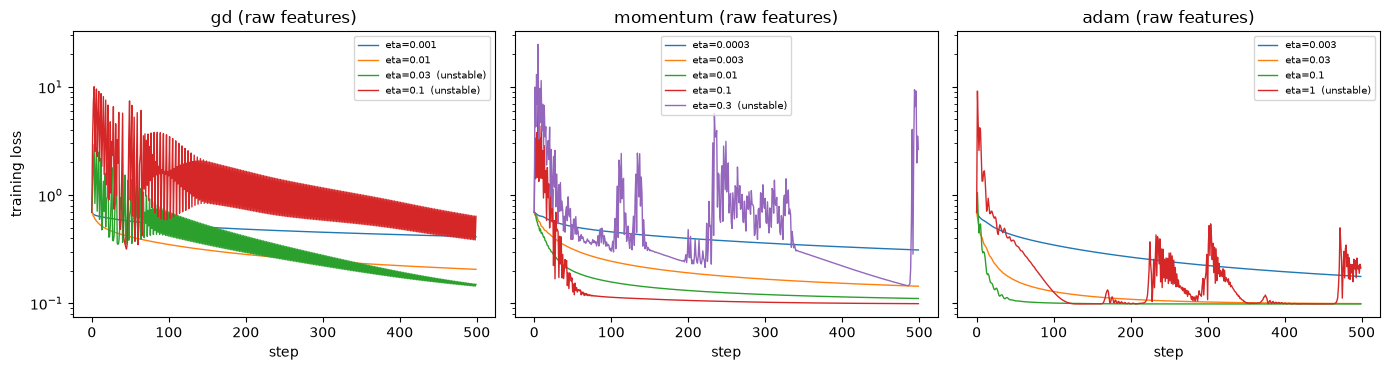


=== standardised features: Hessian at 0 has L = 0.312, kappa = 1.63, 2/L = 6.42
  gd       : best eta = 3, final loss = 0.1311 (unpenalised 0.1028), training accuracy = 0.968
  momentum : best eta = 1, final loss = 0.1311 (unpenalised 0.1027), training accuracy = 0.968


  adam     : best eta = 0.1, final loss = 0.1311 (unpenalised 0.1027), training accuracy = 0.968


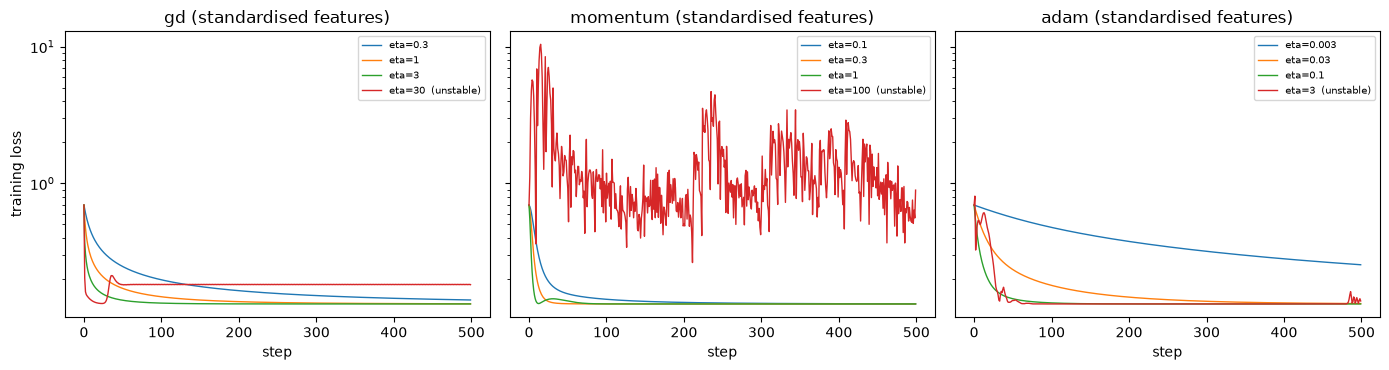


Discussion: on raw features the Hessian's condition number is about a thousand, so plain GD must use a tiny step and
barely moves in the flat directions; momentum improves by roughly sqrt(kappa); Adam is nearly indifferent to the scales
but has its own learning-rate window. Standardising removes most of the conditioning problem and lets all three methods
converge in a few hundred steps. The two optima differ noticeably (penalised loss ~0.098 raw vs ~0.131 standardised) because
the ridge penalty is not scale-invariant: standardising multiplies the penalty on feature j by its variance (up to ~1000x here),
so compare the set-ups by accuracy or unpenalised loss, not by the penalised objective. Recommendation: standardise, sweep the
learning rate, prefer momentum/Adam, and validate on held-out data -- the training accuracy reported above is optimistic.


In [21]:
r = np.random.default_rng(1)
scales = np.logspace(0, 1.5, 10)
X = r.normal(size=(400, 10)) * scales
w_true = r.normal(size=10) / scales
y = (X @ w_true + 0.5 * r.normal(size=400) > 0).astype(float)
lam = 1e-3

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def loss_and_grad(w, Xb, y):
    z = Xb @ w; p = sigmoid(z)
    loss = np.mean(y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z)) + 0.5 * lam * (w[1:] @ w[1:])
    g = Xb.T @ (p - y) / len(y); g[1:] += lam * w[1:]
    return loss, g

def train(Xb, y, method, eta, steps=500, beta=0.9, beta1=0.9, beta2=0.999, eps=1e-8):
    w = np.zeros(Xb.shape[1]); v = np.zeros_like(w); m = np.zeros_like(w); hist = []
    for t in range(1, steps + 1):
        loss, g = loss_and_grad(w, Xb, y); hist.append(loss)
        if not np.isfinite(loss):
            break
        if method == "gd":
            w = w - eta * g
        elif method == "momentum":
            v = beta * v + g; w = w - eta * v
        elif method == "adam":
            m = beta1 * m + (1 - beta1) * g; v = beta2 * v + (1 - beta2) * g * g
            w = w - eta * (m / (1 - beta1 ** t)) / (np.sqrt(v / (1 - beta2 ** t)) + eps)
    return w, np.array(hist)

grids = {"gd": [1e-3, 1e-2, 3e-2, 1e-1], "momentum": [3e-4, 3e-3, 1e-2, 1e-1, 3e-1], "adam": [3e-3, 3e-2, 1e-1, 1.0]}
grids_std = {"gd": [0.3, 1.0, 3.0, 30.0], "momentum": [0.1, 0.3, 1.0, 100.0], "adam": [3e-3, 3e-2, 1e-1, 3.0]}
for title, Xf, grid in [("raw features", X, grids), ("standardised features", (X - X.mean(0)) / X.std(0), grids_std)]:
    Xb = np.c_[np.ones(len(Xf)), Xf]
    H0 = 0.25 * Xb.T @ Xb / len(y); ev = np.linalg.eigvalsh(H0)
    print(f"\n=== {title}: Hessian at 0 has L = {ev[-1]:.3g}, kappa = {ev[-1] / max(ev[0], 1e-12):.3g}, 2/L = {2 / ev[-1]:.3g}")
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
    for ax, method in zip(axes, grid):
        best = None
        for eta in grid[method]:
            w, hist = train(Xb, y, method, eta)
            # unstable = diverged, ended above the start, or still oscillating: the loss rose in more than 5 of the last 50 steps
            unstable = len(hist) < 500 or not np.isfinite(hist[-1]) or hist[-1] > hist[0] or np.sum(np.diff(hist[-50:]) > 1e-9) > 5
            ax.semilogy(hist, lw=1, label=f"eta={eta:g}" + ("  (unstable)" if unstable else ""))
            if not unstable and (best is None or hist[-1] < best[1]):
                z = Xb @ w
                best = (eta, hist[-1], np.mean((z > 0) == (y == 1)), np.mean(y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z)))
        ax.set_title(f"{method} ({title})"); ax.set_xlabel("step"); ax.legend(fontsize=7)
        if best:
            print(f"  {method:9s}: best eta = {best[0]:g}, final loss = {best[1]:.4f} (unpenalised {best[3]:.4f}), training accuracy = {best[2]:.3f}")
    axes[0].set_ylabel("training loss"); plt.tight_layout(); plt.show()
print("\nDiscussion: on raw features the Hessian's condition number is about a thousand, so plain GD must use a tiny step and")
print("barely moves in the flat directions; momentum improves by roughly sqrt(kappa); Adam is nearly indifferent to the scales")
print("but has its own learning-rate window. Standardising removes most of the conditioning problem and lets all three methods")
print("converge in a few hundred steps. The two optima differ noticeably (penalised loss ~0.098 raw vs ~0.131 standardised) because")
print("the ridge penalty is not scale-invariant: standardising multiplies the penalty on feature j by its variance (up to ~1000x here),")
print("so compare the set-ups by accuracy or unpenalised loss, not by the penalised objective. Recommendation: standardise, sweep the")
print("learning rate, prefer momentum/Adam, and validate on held-out data -- the training accuracy reported above is optimistic.")

## Score

In [22]:
summary()


Score: 48/48 checks passed  🎉
